In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

Libraries imported successfully!
TensorFlow Version: 2.21.0


In [2]:
df = pd.read_csv("dataset/train.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [3]:
X = df.drop(columns=["price_range", "id"], errors="ignore")
y = df["price_range"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nPrice Categories:")
print(y.value_counts().sort_index())

Input Features Shape: (2000, 20)
Target Shape: (2000,)

Price Categories:
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1600, 20)
Testing Data: (400, 20)


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")
print("\nFirst 5 Scaled Samples:")
print(X_train_scaled[:5])

Feature Scaling Completed!

First 5 Scaled Samples:
[[ 1.38919326  1.011314   -1.25918898  0.98634324  1.30925256 -1.03693152
   1.58482903 -0.70458975 -1.25033529 -1.5516371   0.35023908 -0.79884868
  -1.28564151 -0.36302366 -0.78128983 -0.17762722 -0.89664506 -1.78870765
  -1.00878862 -1.02532046]
 [ 0.07840603  1.011314   -1.25918898 -1.01384584  1.77045998 -1.03693152
  -0.00345726 -1.39684863 -0.76837395  1.0731587   0.84454887  1.58230174
   1.63767503 -1.54789561  0.64708236  1.87520744  0.56094407 -1.78870765
  -1.00878862  0.97530483]
 [-1.02457347 -0.98881258  1.18747125  0.98634324 -0.0743697   0.96438384
   1.36575506  1.37218691 -1.39208862  1.51062466  0.35023908 -1.36150237
  -0.19930538  1.69898521 -0.06710374  0.506651   -0.89664506  0.55906285
   0.99128795  0.97530483]
 [ 0.38669222 -0.98881258 -1.25918898  0.98634324 -0.53557712  0.96438384
   0.10607972  1.02605747 -1.19363396 -0.67670517 -0.80315042  0.83284703
   0.27858927  1.64923164 -0.78128983  0.506651   -1.

In [6]:
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),

    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dense(4, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,556 (13.89 KB)

 Trainable params: 3,556 (13.89 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MLP Model Compiled Successfully!")

MLP Model Compiled Successfully!


In [8]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("MLP Model Training Completed!")

Epoch 1/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3695 - loss: 1.3515 - val_accuracy: 0.4437 - val_loss: 1.2360
Epoch 2/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5594 - loss: 1.1107 - val_accuracy: 0.6187 - val_loss: 1.0015
Epoch 3/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6805 - loss: 0.8725 - val_accuracy: 0.6969 - val_loss: 0.7971
Epoch 4/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7664 - loss: 0.6851 - val_accuracy: 0.7781 - val_loss: 0.6460
Epoch 5/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8320 - loss: 0.5537 - val_accuracy: 0.8438 - val_loss: 0.5374
Epoch 6/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8594 - loss: 0.4620 - val_accuracy: 0.8438 - val_loss: 0.4677
Epoch 7/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9055 - loss: 0.3897 - val_accuracy: 0.8750 - val_loss: 0.4082
Epoch 8/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9234 - loss: 0.3328 - val_accuracy: 0.8938 - val_loss:

In [9]:
y_probability = model.predict(X_test_scaled)

y_pred = np.argmax(y_probability, axis=1)

print("Actual Values:")
print(y_test.values[:20])

print("\nPredicted Values:")
print(y_pred[:20])

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Actual Values:
[3 1 0 2 3 2 0 0 1 0 3 0 0 1 3 3 2 0 1 3]

Predicted Values:
[3 1 0 2 3 2 0 0 1 0 3 0 0 1 3 3 2 0 1 3]


In [10]:
accuracy = accuracy_score(y_test, y_pred)

print("MLP Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

MLP Model Accuracy: 93.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       100
           1       0.94      0.89      0.91       100
           2       0.90      0.92      0.91       100
           3       0.95      0.94      0.94       100

    accuracy                           0.93       400
   macro avg       0.93      0.93      0.93       400
weighted avg       0.93      0.93      0.93       400



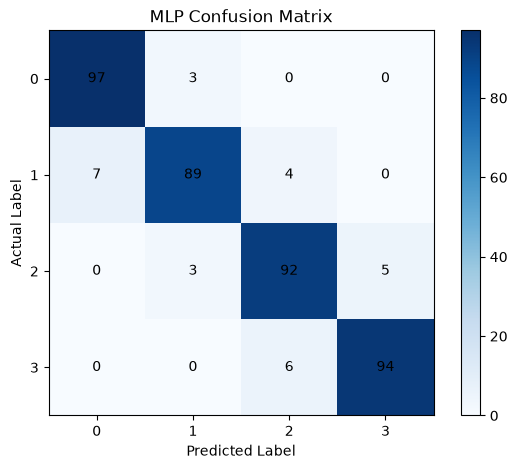

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap="Blues")
plt.title("MLP Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1, 2, 3])
plt.yticks([0, 1, 2, 3])

for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

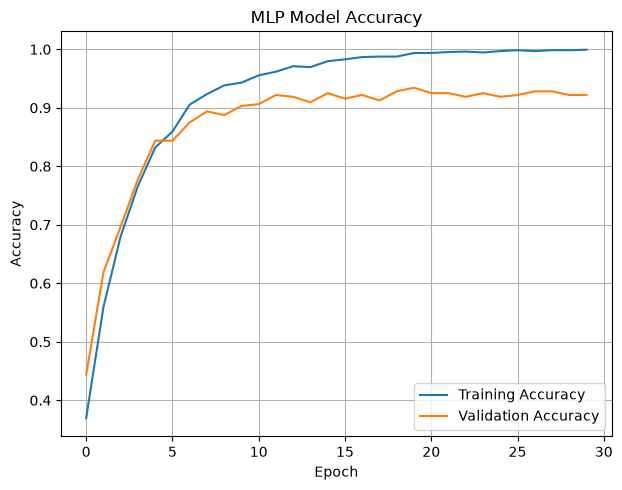

In [14]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MLP Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

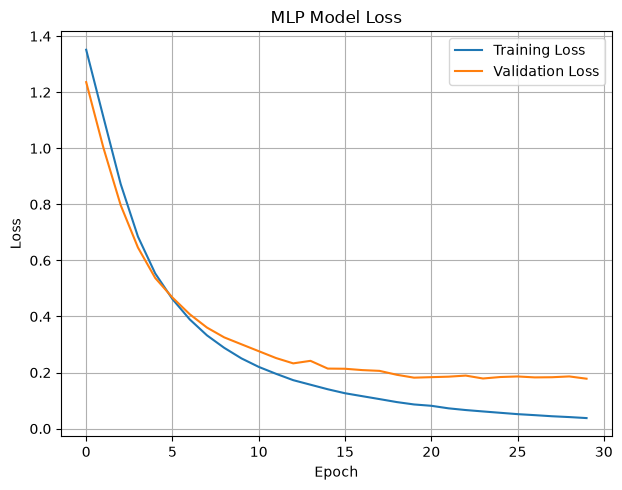

In [13]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("MLP Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()